# Quantum Circuit Bench — Final Level 2 Hardware Experiment

This is the final controlled hardware experiment for the project.

It compares **Model A, Model B, Model C, and topology-valid random controls** across **ibm_fez, ibm_marrakesh, and ibm_kingston** using the same 3-qubit GHZ benchmark.

### Safety / QPU budget guardrails
- `RUN_HARDWARE = False` by default.
- Review the generated manifest before enabling hardware.
- Default is **256 shots** and **1 execution per group**.
- The notebook creates a fixed manifest so the experiment is reproducible.
- It checks backend status before submission.
- It does not automatically increase repeats or shots.
- With defaults: 3 models + 3 random controls × 3 backends = **18 jobs**.

This is deliberately a final pilot, not an uncontrolled QPU sweep.

In [13]:
from pathlib import Path
import os, json, random
import numpy as np
import pandas as pd
from dotenv import load_dotenv

# ---- configuration ----
RUN_HARDWARE = True       # CHANGE TO True only after reviewing the manifest
SHOTS = 256
REPEATS_PER_GROUP = 1
RANDOM_CONTROLS_PER_BACKEND = 3

BACKENDS = ["ibm_fez", "ibm_marrakesh", "ibm_kingston"]
MODELS = ["model_a", "model_b", "model_c"]
RANDOM_SEED = 20260823

RESULT_DIR = Path("results/final_level2")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("RUN_HARDWARE:", RUN_HARDWARE)
print("SHOTS:", SHOTS)
print("REPEATS_PER_GROUP:", REPEATS_PER_GROUP)
print("RANDOM_CONTROLS_PER_BACKEND:", RANDOM_CONTROLS_PER_BACKEND)

RUN_HARDWARE: True
SHOTS: 256
REPEATS_PER_GROUP: 1
RANDOM_CONTROLS_PER_BACKEND: 3


In [14]:
load_dotenv()

TOKEN = os.getenv("IBM_QUANTUM_TOKEN")
INSTANCE = os.getenv("IBM_INSTANCE")

if not TOKEN or not INSTANCE:
    raise RuntimeError(
        "IBM_QUANTUM_TOKEN and IBM_INSTANCE must be present in .env"
    )

print("IBM credentials: FOUND")

IBM credentials: FOUND


## 1. Load the current Railway snapshot

This uses the working QubitTelemetry `database.py`. Keep that file importable from the notebook's project directory.

In [15]:
from pathlib import Path
import sys
import pandas as pd

# ============================================================
# QubitTelemetry Railway connection
# ============================================================

PROJECT_ROOT = Path.cwd()

RAILWAY_DB = PROJECT_ROOT / "railway_db.py"

if not RAILWAY_DB.exists():
    raise FileNotFoundError(
        f"railway_db.py not found at:\n{RAILWAY_DB}\n\n"
        "Place this notebook in the ibm_circuits project root."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from railway_db import get_connection

print("railway_db.py: FOUND")
print("Path:", RAILWAY_DB)

# ============================================================
# Connect to Railway
# ============================================================

conn = get_connection()

# ============================================================
# Latest calibration snapshot
# ============================================================

calibration = pd.read_sql(
    """
    SELECT
        backend,
        qubit,
        T1_us,
        T2_us,
        readout_error,
        snapshot_date
    FROM calibration_history
    WHERE snapshot_date = (
        SELECT MAX(snapshot_date)
        FROM calibration_history
    )
    """,
    conn,
)

# ============================================================
# Latest Model A/B/C rankings
# ============================================================

rankings = pd.read_sql(
    """
    SELECT
        model_name,
        backend,
        qubit,
        snapshot_date,
        viability_score,
        viability_rank
    FROM qubit_rankings
    WHERE snapshot_date = (
        SELECT MAX(snapshot_date)
        FROM qubit_rankings
    )
    """,
    conn,
)

conn.close()

# ============================================================
# Validate
# ============================================================

if calibration.empty:
    raise RuntimeError(
        "Railway returned ZERO calibration rows."
    )

if rankings.empty:
    raise RuntimeError(
        "Railway returned ZERO ranking rows."
    )

snapshot_date = calibration["snapshot_date"].iloc[0]

print()
print("=" * 60)
print("RAILWAY DATA VALIDATION")
print("=" * 60)

print("Snapshot       :", snapshot_date)
print("Calibration    :", len(calibration))
print("Rankings       :", len(rankings))

print(
    "Backends       :",
    sorted(calibration["backend"].unique())
)

print(
    "Models         :",
    sorted(rankings["model_name"].unique())
)

expected_models = {
    "model_a",
    "model_b",
    "model_c",
}

actual_models = set(
    rankings["model_name"].unique()
)

missing_models = expected_models - actual_models

if missing_models:
    raise RuntimeError(
        f"Missing models in Railway: {sorted(missing_models)}"
    )

print("STATUS         : PASS")

railway_db.py: FOUND
Path: D:\Downloads\uday projects\ibm_circuits\railway_db.py


C:\Users\VATTIKUTI UDAY KIRAN\AppData\Local\Temp\ipykernel_36248\708570136.py:36: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  calibration = pd.read_sql(
C:\Users\VATTIKUTI UDAY KIRAN\AppData\Local\Temp\ipykernel_36248\708570136.py:58: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  rankings = pd.read_sql(



RAILWAY DATA VALIDATION
Snapshot       : 2026-08-23
Calibration    : 466
Rankings       : 1398
Backends       : ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Models         : ['model_a', 'model_b', 'model_c']
STATUS         : PASS


In [16]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=TOKEN,
    instance=INSTANCE,
)

print("IBM authentication: PASS")

def connected_3q_chains(backend):
    edges = list(backend.coupling_map.get_edges())
    undirected = {tuple(sorted((int(a), int(b)))) for a, b in edges}

    adjacency = {}
    for a, b in undirected:
        adjacency.setdefault(a, set()).add(b)
        adjacency.setdefault(b, set()).add(a)

    chains = set()
    for center, neighbors in adjacency.items():
        neighbors = sorted(neighbors)
        for i in range(len(neighbors)):
            for j in range(i + 1, len(neighbors)):
                a, b = neighbors[i], neighbors[j]
                chains.add(tuple(sorted((a, center, b))))

    return sorted(chains)

def best_model_chain(backend_name, model_name, chains):
    r = rankings[
        (rankings.backend == backend_name) &
        (rankings.model_name == model_name)
    ]

    scores = r.set_index("qubit")["viability_score"].to_dict()
    valid = [c for c in chains if all(q in scores for q in c)]

    if not valid:
        raise RuntimeError(
            f"No valid connected chain for {backend_name}/{model_name}"
        )

    return max(
        valid,
        key=lambda c: (
            np.mean([scores[q] for q in c]),
            min(scores[q] for q in c),
        ),
    )

rng = random.Random(RANDOM_SEED)
manifest = []

for backend_name in BACKENDS:
    backend = service.backend(backend_name)
    chains = connected_3q_chains(backend)

    print(f"{backend_name}: {len(chains)} connected 3-qubit chains")

    model_chains = set()

    for model_name in MODELS:
        chain = best_model_chain(backend_name, model_name, chains)
        model_chains.add(chain)

        manifest.append({
            "backend": backend_name,
            "group": model_name,
            "qubits": list(chain),
            "snapshot_date": str(snapshot_date),
        })

    # Random controls are topology-valid and exclude model-selected chains.
    pool = [c for c in chains if c not in model_chains]

    choices = rng.sample(
        pool,
        min(RANDOM_CONTROLS_PER_BACKEND, len(pool)),
    )

    for i, chain in enumerate(choices, 1):
        manifest.append({
            "backend": backend_name,
            "group": f"random_{i}",
            "qubits": list(chain),
            "snapshot_date": str(snapshot_date),
        })

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    RESULT_DIR / "final_experiment_manifest.csv",
    index=False,
)

manifest_df.to_json(
    RESULT_DIR / "final_experiment_manifest.json",
    orient="records",
    indent=2,
)

display(manifest_df)

print("Manifest created. No hardware jobs submitted.")

qiskit_runtime_service._discover_account:WARNING:2026-08-23 23:44:38,452: Loading account with the given token. A saved account will not be used.


IBM authentication: PASS
ibm_fez: 244 connected 3-qubit chains
ibm_marrakesh: 244 connected 3-qubit chains
ibm_kingston: 244 connected 3-qubit chains


,backend,group,qubits,snapshot_date
0,ibm_fez,model_a,"[21, 22, 23]",2026-08-23
1,ibm_fez,model_b,"[21, 22, 23]",2026-08-23
2,ibm_fez,model_c,"[20, 21, 22]",2026-08-23
3,ibm_fez,random_1,"[100, 101, 116]",2026-08-23
4,ibm_fez,random_2,"[137, 147, 148]",2026-08-23
5,ibm_fez,random_3,"[78, 89, 90]",2026-08-23
6,ibm_marrakesh,model_a,"[132, 133, 134]",2026-08-23
7,ibm_marrakesh,model_b,"[1, 2, 3]",2026-08-23
8,ibm_marrakesh,model_c,"[12, 13, 14]",2026-08-23
9,ibm_marrakesh,random_1,"[119, 132, 133]",2026-08-23


Manifest created. No hardware jobs submitted.


In [17]:
planned_jobs = len(manifest_df) * REPEATS_PER_GROUP

print("Planned hardware jobs:", planned_jobs)
print("Expected groups/backend:",
      len(MODELS) + RANDOM_CONTROLS_PER_BACKEND)

if planned_jobs > 24:
    print("WARNING: more than 24 jobs planned.")

print()
print("Review the manifest above.")
print("Only then set RUN_HARDWARE = True.")

Planned hardware jobs: 18
Expected groups/backend: 6

Review the manifest above.
Only then set RUN_HARDWARE = True.


## 2. Hardware execution

The next cell is the only cell that submits QPU jobs.

For the final pilot, the default is one execution per group. If `RUN_HARDWARE` remains `False`, nothing is submitted.

In [18]:
from qiskit import QuantumCircuit, transpile
from qiskit_ibm_runtime import SamplerV2

def build_ghz():
    qc = QuantumCircuit(3, 3)
    qc.h(0)
    qc.cx(0, 1)
    qc.cx(1, 2)
    qc.measure(range(3), range(3))
    return qc

def extract_counts(pub_result):
    data = pub_result.data

    if hasattr(data, "c"):
        return data.c.get_counts()

    for name in dir(data):
        if name.startswith("_"):
            continue
        try:
            obj = getattr(data, name)
            if hasattr(obj, "get_counts"):
                return obj.get_counts()
        except Exception:
            pass

    raise RuntimeError("Could not extract SamplerV2 counts.")

def ghz_fidelity(counts):
    total = sum(counts.values())
    if total == 0:
        raise RuntimeError("Zero shots returned.")
    return (
        counts.get("000", 0) +
        counts.get("111", 0)
    ) / total

def run_one(row, repeat):
    backend_name = row.backend
    group = row.group
    qubits = list(row.qubits)

    backend = service.backend(backend_name)
    status = backend.status()

    if not status.operational:
        raise RuntimeError(
            f"{backend_name} is not operational."
        )

    print()
    print("=" * 60)
    print(f"{backend_name} | {group}")
    print("Qubits:", qubits)
    print("Pending:", status.pending_jobs)

    circuit = build_ghz()

    transpiled = transpile(
        circuit,
        backend=backend,
        initial_layout=qubits,
        optimization_level=1,
    )

    print("Transpiled depth:", transpiled.depth())

    sampler = SamplerV2(mode=backend)

    print("Submitting ONE job...")
    job = sampler.run([transpiled], shots=SHOTS)

    print("JOB ID:", job.job_id())

    result = job.result()[0]
    counts = extract_counts(result)
    fidelity = ghz_fidelity(counts)

    print("Counts:", counts)
    print(f"Fidelity: {fidelity:.4f}")

    return {
        "backend": backend_name,
        "group": group,
        "repeat": repeat,
        "qubits": qubits,
        "shots": SHOTS,
        "job_id": job.job_id(),
        "transpiled_depth": transpiled.depth(),
        "counts": counts,
        "fidelity": fidelity,
        "snapshot_date": str(snapshot_date),
    }

if RUN_HARDWARE:
    hardware_results = []

    for repeat in range(1, REPEATS_PER_GROUP + 1):
        for row in manifest_df.itertuples(index=False):
            hardware_results.append(
                run_one(row, repeat)
            )

    with open(
        RESULT_DIR / "final_hardware_results.json",
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(hardware_results, f, indent=2)

    results_df = pd.DataFrame(hardware_results)

    results_df.to_csv(
        RESULT_DIR / "final_hardware_results.csv",
        index=False,
    )

    print()
    print("FINAL HARDWARE EXPERIMENT COMPLETE.")
else:
    print("DRY RUN: zero QPU jobs submitted.")


ibm_fez | model_a
Qubits: [21, 22, 23]
Pending: 2
Transpiled depth: 12
Submitting ONE job...
JOB ID: da5jhb6aa69c739kundg
Counts: {'111': 121, '011': 6, '000': 124, '100': 1, '101': 2, '110': 2}
Fidelity: 0.9570

ibm_fez | model_b
Qubits: [21, 22, 23]
Pending: 2
Transpiled depth: 12
Submitting ONE job...
JOB ID: da5jhds3jnrc73ahcgk0
Counts: {'000': 135, '111': 114, '100': 1, '101': 1, '011': 4, '110': 1}
Fidelity: 0.9727

ibm_fez | model_c
Qubits: [20, 21, 22]
Pending: 2
Transpiled depth: 12
Submitting ONE job...
JOB ID: da5jhgm1vhnc73fm5k0g
Counts: {'000': 124, '111': 119, '110': 9, '001': 1, '011': 1, '101': 1, '010': 1}
Fidelity: 0.9492

ibm_fez | random_1
Qubits: [100, 101, 116]
Pending: 2
Transpiled depth: 12
Submitting ONE job...
JOB ID: da5jhis3jnrc73ahcgt0
Counts: {'000': 122, '111': 102, '110': 10, '100': 5, '011': 3, '010': 3, '001': 8, '101': 3}
Fidelity: 0.8750

ibm_fez | random_2
Qubits: [137, 147, 148]
Pending: 2
Transpiled depth: 12
Submitting ONE job...
JOB ID: da5jhle

## 3. Final analysis and model/backend profiles

Run after the hardware CSV has been created. The analysis compares each model against the random controls **within each backend**, which is the main comparison needed for the final experiment.

In [19]:
RESULTS_CSV = RESULT_DIR / "final_hardware_results.csv"

if not RESULTS_CSV.exists():
    print("No hardware results yet.")
    print("Run the hardware cell first.")
else:
    final_df = pd.read_csv(RESULTS_CSV)

    final_df["category"] = np.where(
        final_df["group"].isin(MODELS),
        final_df["group"],
        "random",
    )

    display(final_df)

,backend,group,repeat,qubits,shots,job_id,transpiled_depth,counts,fidelity,snapshot_date,category
0,ibm_fez,model_a,1,"[21, 22, 23]",256,da5jhb6aa69c739kundg,12,"{'111': 121, '011': 6, '000': 124, '100': 1, '...",0.957031,2026-08-23,model_a
1,ibm_fez,model_b,1,"[21, 22, 23]",256,da5jhds3jnrc73ahcgk0,12,"{'000': 135, '111': 114, '100': 1, '101': 1, '...",0.972656,2026-08-23,model_b
2,ibm_fez,model_c,1,"[20, 21, 22]",256,da5jhgm1vhnc73fm5k0g,12,"{'000': 124, '111': 119, '110': 9, '001': 1, '...",0.949219,2026-08-23,model_c
3,ibm_fez,random_1,1,"[100, 101, 116]",256,da5jhis3jnrc73ahcgt0,12,"{'000': 122, '111': 102, '110': 10, '100': 5, ...",0.875000,2026-08-23,random
4,ibm_fez,random_2,1,"[137, 147, 148]",256,da5jhleaa69c739kunsg,12,"{'111': 123, '000': 113, '100': 4, '101': 2, '...",0.921875,2026-08-23,random
5,ibm_fez,random_3,1,"[78, 89, 90]",256,da5jhnu1vhnc73fm5kb0,12,"{'111': 118, '000': 124, '001': 2, '110': 6, '...",0.945312,2026-08-23,random
6,ibm_marrakesh,model_a,1,"[132, 133, 134]",256,da5jhqm1vhnc73fm5kdg,12,"{'111': 112, '000': 134, '101': 4, '001': 3, '...",0.960938,2026-08-23,model_a
7,ibm_marrakesh,model_b,1,"[1, 2, 3]",256,da5jht3otlns739c0jlg,12,"{'000': 116, '111': 132, '101': 1, '001': 4, '...",0.968750,2026-08-23,model_b
8,ibm_marrakesh,model_c,1,"[12, 13, 14]",256,da5jhvm1vhnc73fm5kkg,12,"{'000': 127, '111': 117, '011': 3, '100': 2, '...",0.953125,2026-08-23,model_c
9,ibm_marrakesh,random_1,1,"[119, 132, 133]",256,da5ji1rotlns739c0js0,18,"{'111': 116, '001': 21, '000': 96, '110': 11, ...",0.828125,2026-08-23,random


In [20]:
if RESULTS_CSV.exists():
    # Backend/model profile
    profiles = (
        final_df
        .groupby(["backend", "category"])["fidelity"]
        .agg(["count", "mean", "std", "min", "max"])
        .reset_index()
    )

    random_means = (
        final_df[final_df.category == "random"]
        .groupby("backend")["fidelity"]
        .mean()
        .rename("random_mean")
    )

    profiles = profiles.merge(
        random_means,
        on="backend",
        how="left",
    )

    profiles["improvement_vs_random"] = (
        profiles["mean"] - profiles["random_mean"]
    )

    profiles["relative_improvement_percent"] = (
        100 *
        profiles["improvement_vs_random"] /
        profiles["random_mean"]
    )

    profiles.to_csv(
        RESULT_DIR / "final_model_backend_profiles.csv",
        index=False,
    )

    display(profiles)

,backend,category,count,mean,std,min,max,random_mean,improvement_vs_random,relative_improvement_percent
0,ibm_fez,model_a,1,0.957031,NaN,0.957031,0.957031,0.914062,0.042969,4.700855
1,ibm_fez,model_b,1,0.972656,NaN,0.972656,0.972656,0.914062,0.058594,6.410256
2,ibm_fez,model_c,1,0.949219,NaN,0.949219,0.949219,0.914062,0.035156,3.846154
3,ibm_fez,random,3,0.914062,0.035801,0.875000,0.945312,0.914062,0.000000,0.000000
4,ibm_kingston,model_a,1,0.925781,NaN,0.925781,0.925781,0.953125,-0.027344,-2.868852
5,ibm_kingston,model_b,1,0.980469,NaN,0.980469,0.980469,0.953125,0.027344,2.868852
6,ibm_kingston,model_c,1,0.968750,NaN,0.968750,0.968750,0.953125,0.015625,1.639344
7,ibm_kingston,random,3,0.953125,0.023438,0.929688,0.976562,0.953125,0.000000,0.000000
8,ibm_marrakesh,model_a,1,0.960938,NaN,0.960938,0.960938,0.873698,0.087240,9.985097
9,ibm_marrakesh,model_b,1,0.968750,NaN,0.968750,0.968750,0.873698,0.095052,10.879285


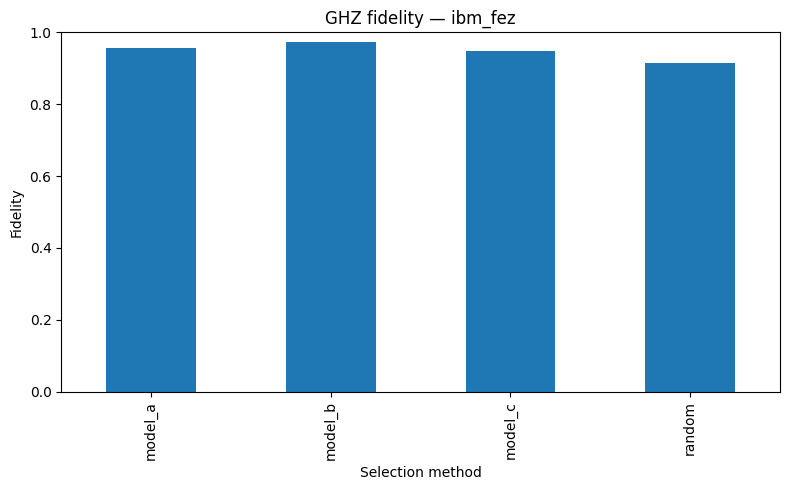

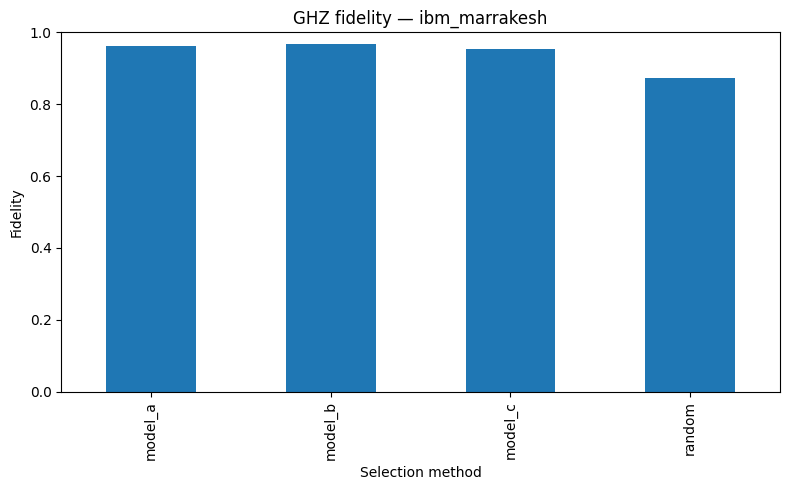

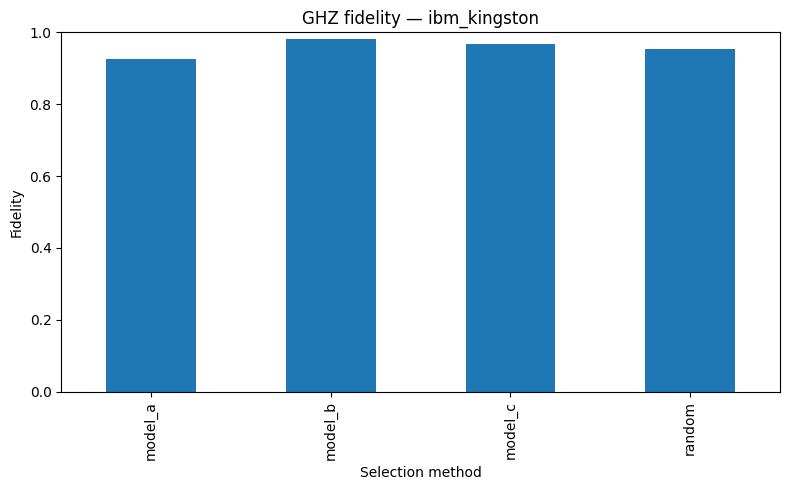

<Figure size 900x500 with 0 Axes>

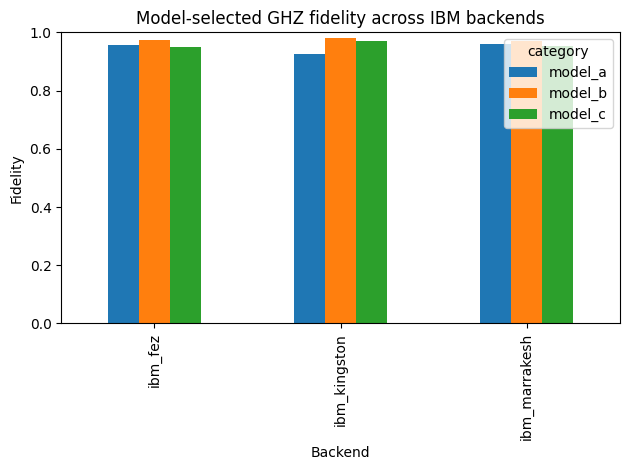

<Figure size 900x500 with 0 Axes>

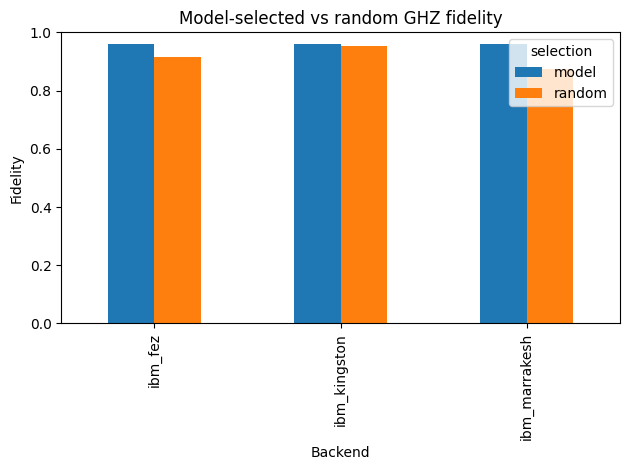

<Figure size 900x500 with 0 Axes>

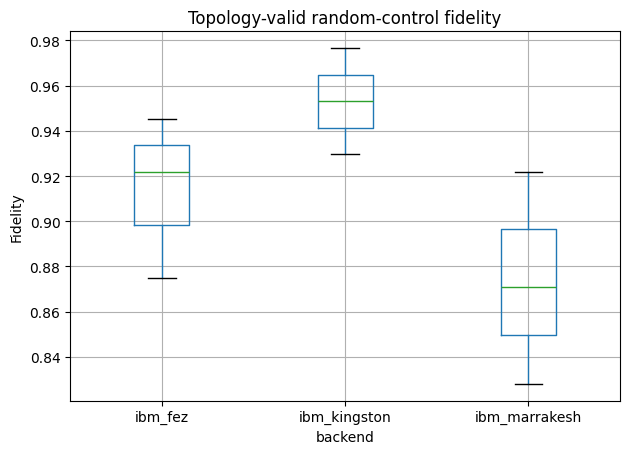

In [21]:
if RESULTS_CSV.exists():
    import matplotlib.pyplot as plt

    # 1. Individual backend profiles
    for backend_name in BACKENDS:
        subset = final_df[
            final_df.backend == backend_name
        ]

        means = (
            subset.groupby("category")["fidelity"]
            .mean()
            .reindex(MODELS + ["random"])
        )

        plt.figure(figsize=(8, 5))
        means.plot(kind="bar")
        plt.title(
            f"GHZ fidelity — {backend_name}"
        )
        plt.ylabel("Fidelity")
        plt.xlabel("Selection method")
        plt.ylim(0, 1)
        plt.tight_layout()
        plt.savefig(
            RESULT_DIR /
            f"{backend_name}_model_profile.png",
            dpi=200,
        )
        plt.show()

    # 2. All models across all backends
    model_subset = final_df[
        final_df.category.isin(MODELS)
    ]

    pivot = model_subset.pivot_table(
        index="backend",
        columns="category",
        values="fidelity",
        aggfunc="mean",
    )

    plt.figure(figsize=(9, 5))
    pivot.plot(kind="bar")
    plt.title(
        "Model-selected GHZ fidelity across IBM backends"
    )
    plt.ylabel("Fidelity")
    plt.xlabel("Backend")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR /
        "all_models_all_backends.png",
        dpi=200,
    )
    plt.show()

    # 3. Model vs random
    compare = final_df.copy()
    compare["selection"] = np.where(
        compare.category == "random",
        "random",
        "model",
    )

    compare_means = (
        compare.groupby(
            ["backend", "selection"]
        )["fidelity"]
        .mean()
        .unstack()
    )

    plt.figure(figsize=(9, 5))
    compare_means.plot(kind="bar")
    plt.title(
        "Model-selected vs random GHZ fidelity"
    )
    plt.ylabel("Fidelity")
    plt.xlabel("Backend")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR /
        "model_vs_random_all_backends.png",
        dpi=200,
    )
    plt.show()

    # 4. Random-control distributions
    random_only = final_df[
        final_df.category == "random"
    ]

    plt.figure(figsize=(9, 5))
    random_only.boxplot(
        column="fidelity",
        by="backend",
    )
    plt.suptitle("")
    plt.title(
        "Topology-valid random-control fidelity"
    )
    plt.ylabel("Fidelity")
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR /
        "random_control_distributions.png",
        dpi=200,
    )
    plt.show()

## 4. Final interpretation rules

The final paper should report:

- Model A/B/C separately for each backend.
- Random controls separately for each backend.
- Mean, spread, and number of executions.
- Transpiled circuit depth.
- Improvement versus the within-backend random baseline.
- Whether the model advantage is consistent across backends.

Do **not** call a result statistically significant merely because a model mean is higher than the random mean. Repeated model executions and an appropriate statistical test are required for that claim.

The most important research question is:

> **Does model-guided qubit selection consistently improve circuit-level GHZ fidelity relative to topology-valid random selection across multiple IBM backends?**

If the answer is mixed, report the mixed result and use it to motivate the next circuit-aware model.

In [23]:
df = pd.read_csv("results/final_level2/final_hardware_results.csv")

print(df.columns.tolist())
print(df)

['backend', 'group', 'repeat', 'qubits', 'shots', 'job_id', 'transpiled_depth', 'counts', 'fidelity', 'snapshot_date']
          backend     group  repeat           qubits  shots  \
0         ibm_fez   model_a       1     [21, 22, 23]    256   
1         ibm_fez   model_b       1     [21, 22, 23]    256   
2         ibm_fez   model_c       1     [20, 21, 22]    256   
3         ibm_fez  random_1       1  [100, 101, 116]    256   
4         ibm_fez  random_2       1  [137, 147, 148]    256   
5         ibm_fez  random_3       1     [78, 89, 90]    256   
6   ibm_marrakesh   model_a       1  [132, 133, 134]    256   
7   ibm_marrakesh   model_b       1        [1, 2, 3]    256   
8   ibm_marrakesh   model_c       1     [12, 13, 14]    256   
9   ibm_marrakesh  random_1       1  [119, 132, 133]    256   
10  ibm_marrakesh  random_2       1     [22, 23, 24]    256   
11  ibm_marrakesh  random_3       1  [121, 122, 123]    256   
12   ibm_kingston   model_a       1  [152, 153, 154]    256   

In [25]:
import os
from pathlib import Path
from dotenv import load_dotenv
from qiskit_ibm_runtime import QiskitRuntimeService

# Find project root
PROJECT_ROOT = Path.cwd()

# If notebook is inside notebooks/, move one level up
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load .env
load_dotenv(PROJECT_ROOT / ".env")

IBM_QUANTUM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN")
IBM_INSTANCE = os.getenv("IBM_INSTANCE")

if not IBM_QUANTUM_TOKEN:
    raise RuntimeError("IBM_QUANTUM_TOKEN not found in .env")

if not IBM_INSTANCE:
    raise RuntimeError("IBM_INSTANCE not found in .env")

print("IBM token: FOUND")
print("IBM instance: FOUND")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=IBM_QUANTUM_TOKEN,
    instance=IBM_INSTANCE
)

backend = service.backend("ibm_fez")

print("Backend:", backend.name)
print("Qubits:", backend.num_qubits)
print("Topology loaded.")

qiskit_runtime_service._discover_account:WARNING:2026-08-24 01:57:36,224: Loading account with the given token. A saved account will not be used.


IBM token: FOUND
IBM instance: FOUND
Backend: ibm_fez
Qubits: 156
Topology loaded.


In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
from qiskit_ibm_runtime import QiskitRuntimeService

# ---------------------------------------------------------
# IBM Quantum connection
# Uses your existing environment variables
# ---------------------------------------------------------

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=IBM_QUANTUM_TOKEN,
    instance=IBM_INSTANCE
)

backend = service.backend("ibm_fez")

# ---------------------------------------------------------
# Build physical coupling graph
# ---------------------------------------------------------

G = nx.Graph()

edges = backend.coupling_map.get_edges()

for q1, q2 in edges:
    G.add_edge(q1, q2)

# Model-selected chains from final experiment
model_a = [21, 22, 23]
model_b = [21, 22, 23]
model_c = [20, 21, 22]

# Highlight the union of selected qubits
selected_qubits = sorted(set(model_a + model_b + model_c))

# ---------------------------------------------------------
# Layout
# ---------------------------------------------------------

pos = nx.spring_layout(
    G,
    seed=42,
    iterations=100
)

plt.figure(figsize=(15, 11))

# Entire hardware topology
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.12,
    width=0.7
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=30,
    alpha=0.65
)

# Selected qubits
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=selected_qubits,
    node_size=180
)

# Labels only for selected qubits
nx.draw_networkx_labels(
    G,
    pos,
    labels={q: str(q) for q in selected_qubits},
    font_size=9
)

plt.title(
    "IBM Quantum ibm_fez — Physical Qubit Topology\n"
    "Model-selected qubits from the final hardware experiment",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/level2_topology_model_selected.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/level2_topology_model_selected.png")

qiskit_runtime_service._discover_account:WARNING:2026-08-24 01:59:19,252: Loading account with the given token. A saved account will not be used.


InvalidAccountError: 'Unable to retrieve instances. Please check that you are using a valid API token.'

In [27]:
import os
from pathlib import Path
from dotenv import load_dotenv

from qiskit_ibm_runtime import QiskitRuntimeService

# ---------------------------------------------------------
# Load .env
# ---------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env", override=True)

token = os.getenv("IBM_QUANTUM_TOKEN")
instance = os.getenv("IBM_INSTANCE")

print("Token:", "FOUND" if token else "MISSING")
print("Instance:", "FOUND" if instance else "MISSING")

# ---------------------------------------------------------
# Connect
# ---------------------------------------------------------

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=token,
    instance=instance
)

print("Authentication: PASS")

backend = service.backend("ibm_fez")

print("Backend:", backend.name)
print("Qubits:", backend.num_qubits)
print("Topology edges:", len(backend.coupling_map.get_edges()))

qiskit_runtime_service._discover_account:WARNING:2026-08-24 02:00:59,997: Loading account with the given token. A saved account will not be used.


Token: FOUND
Instance: FOUND
Authentication: PASS
Backend: ibm_fez
Qubits: 156
Topology edges: 352


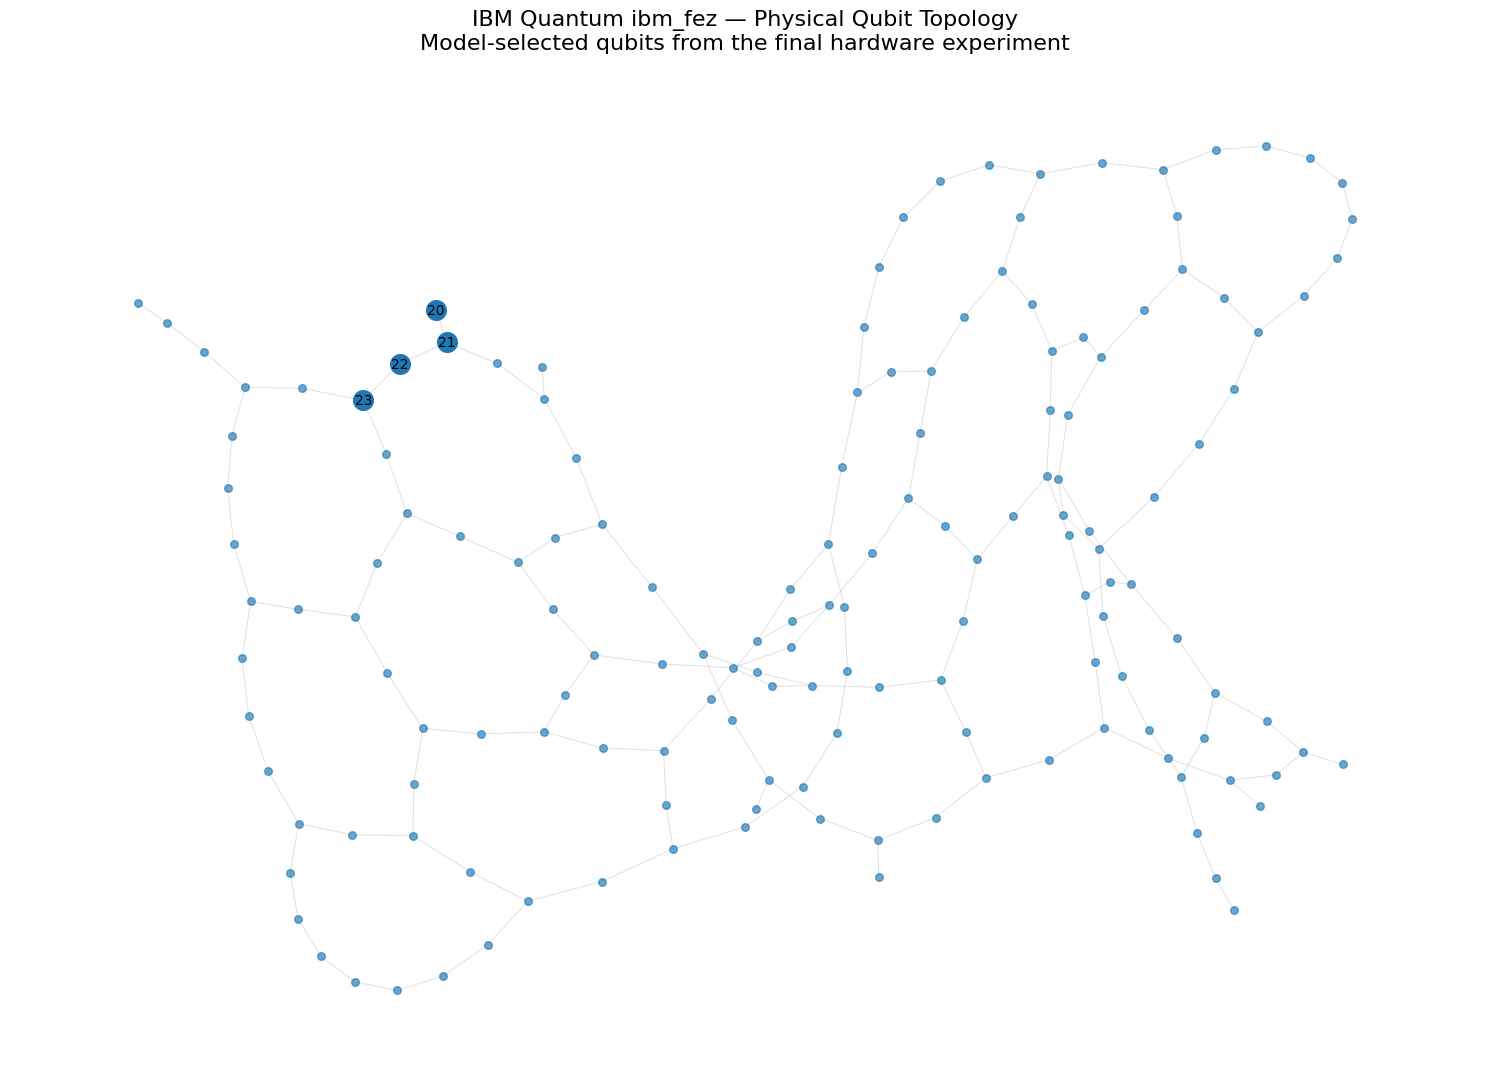

Saved: figures\level2_topology_model_selected.png


In [28]:
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path

# ---------------------------------------------------------
# Build IBM Fez physical topology
# ---------------------------------------------------------

G = nx.Graph()

for q1, q2 in backend.coupling_map.get_edges():
    G.add_edge(q1, q2)

# Model-selected qubits from final experiment
model_a = [21, 22, 23]
model_b = [21, 22, 23]
model_c = [20, 21, 22]

selected_qubits = sorted(
    set(model_a + model_b + model_c)
)

# ---------------------------------------------------------
# Layout
# ---------------------------------------------------------

pos = nx.spring_layout(
    G,
    seed=42,
    iterations=100
)

plt.figure(figsize=(15, 11))

# Full physical topology
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.12,
    width=0.7
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=30,
    alpha=0.65
)

# Highlight selected physical qubits
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=selected_qubits,
    node_size=200
)

# Label selected qubits
nx.draw_networkx_labels(
    G,
    pos,
    labels={
        q: str(q)
        for q in selected_qubits
    },
    font_size=10
)

plt.title(
    "IBM Quantum ibm_fez — Physical Qubit Topology\n"
    "Model-selected qubits from the final hardware experiment",
    fontsize=16
)

plt.axis("off")
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

output = Path(
    "figures/level2_topology_model_selected.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved: {output}")

FINAL HARDWARE MODEL VS RANDOM COMPARISON
group          model_a  model_b  model_c  random_mean  model_a_minus_random  \
backend                                                                       
ibm_fez         0.9570   0.9727   0.9492       0.9141                0.0430   
ibm_kingston    0.9258   0.9805   0.9688       0.9531               -0.0273   
ibm_marrakesh   0.9609   0.9688   0.9531       0.8737                0.0872   

group          model_b_minus_random  model_c_minus_random  
backend                                                    
ibm_fez                      0.0586                0.0352  
ibm_kingston                 0.0273                0.0156  
ibm_marrakesh                0.0951                0.0794  


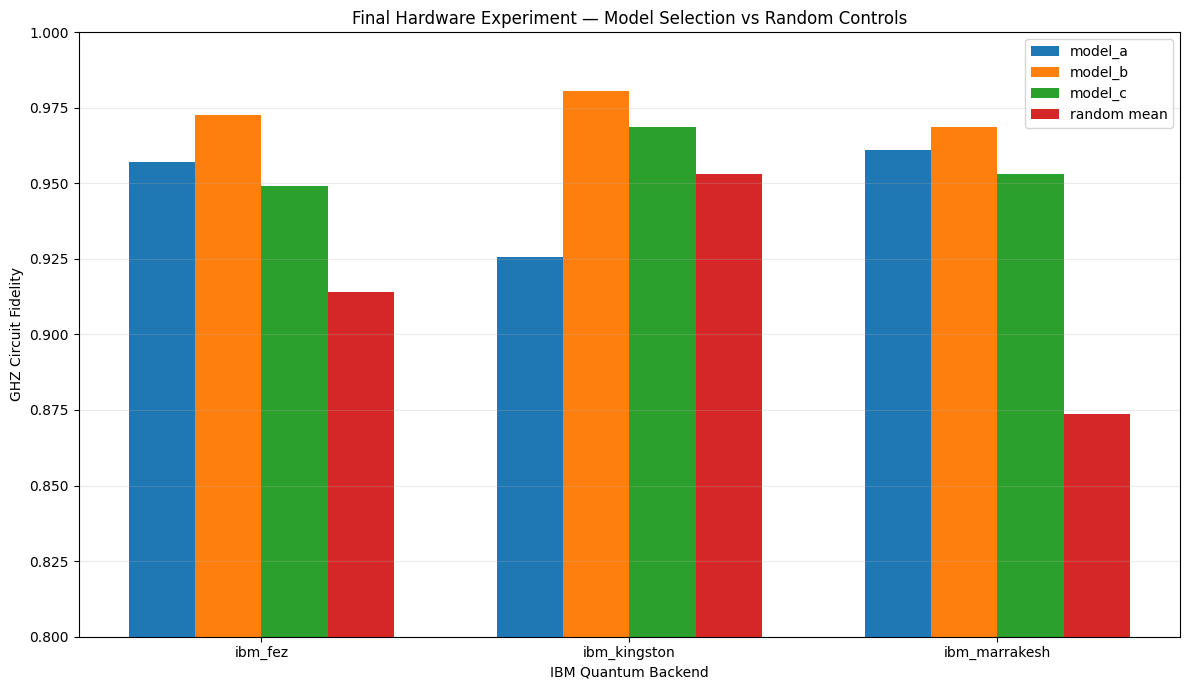


Saved: figures\final_hardware_model_vs_random.png


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# Load final hardware results
# ---------------------------------------------------------

RESULTS_CSV = Path("results/final_level2/final_hardware_results.csv")

df = pd.read_csv(RESULTS_CSV)

backend_order = [
    "ibm_fez",
    "ibm_kingston",
    "ibm_marrakesh"
]

model_order = [
    "model_a",
    "model_b",
    "model_c"
]

# ---------------------------------------------------------
# Model results
# ---------------------------------------------------------

model_df = (
    df[df["group"].isin(model_order)]
    .groupby(["backend", "group"])["fidelity"]
    .mean()
    .unstack()
    .reindex(backend_order)
)

# ---------------------------------------------------------
# Random-control mean
# ---------------------------------------------------------

random_df = df[
    df["group"].isin(["random_1", "random_2", "random_3"])
]

random_mean = (
    random_df
    .groupby("backend")["fidelity"]
    .mean()
    .reindex(backend_order)
)

# ---------------------------------------------------------
# Print exact comparison
# ---------------------------------------------------------

comparison = model_df.copy()
comparison["random_mean"] = random_mean

for model in model_order:
    comparison[f"{model}_minus_random"] = (
        comparison[model] - comparison["random_mean"]
    )

print("=" * 75)
print("FINAL HARDWARE MODEL VS RANDOM COMPARISON")
print("=" * 75)
print(comparison.round(4))

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

x = range(len(backend_order))
width = 0.18

plt.figure(figsize=(12, 7))

for i, model in enumerate(model_order):
    positions = [
        p + (i - 1.5) * width
        for p in x
    ]

    plt.bar(
        positions,
        model_df[model].values,
        width=width,
        label=model
    )

random_positions = [
    p + 1.5 * width
    for p in x
]

plt.bar(
    random_positions,
    random_mean.values,
    width=width,
    label="random mean"
)

plt.xticks(
    list(x),
    backend_order
)

plt.xlabel("IBM Quantum Backend")
plt.ylabel("GHZ Circuit Fidelity")

plt.title(
    "Final Hardware Experiment — Model Selection vs Random Controls"
)

plt.ylim(0.80, 1.00)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.legend()

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

output = Path(
    "figures/final_hardware_model_vs_random.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved: {output}")

RANDOM HARDWARE CONTROL RESULTS
ibm_fez: mean=0.9141, min=0.8750, max=0.9453
ibm_kingston: mean=0.9531, min=0.9297, max=0.9766
ibm_marrakesh: mean=0.8737, min=0.8281, max=0.9219


C:\Users\VATTIKUTI UDAY KIRAN\AppData\Local\Temp\ipykernel_36248\3754618762.py:55: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


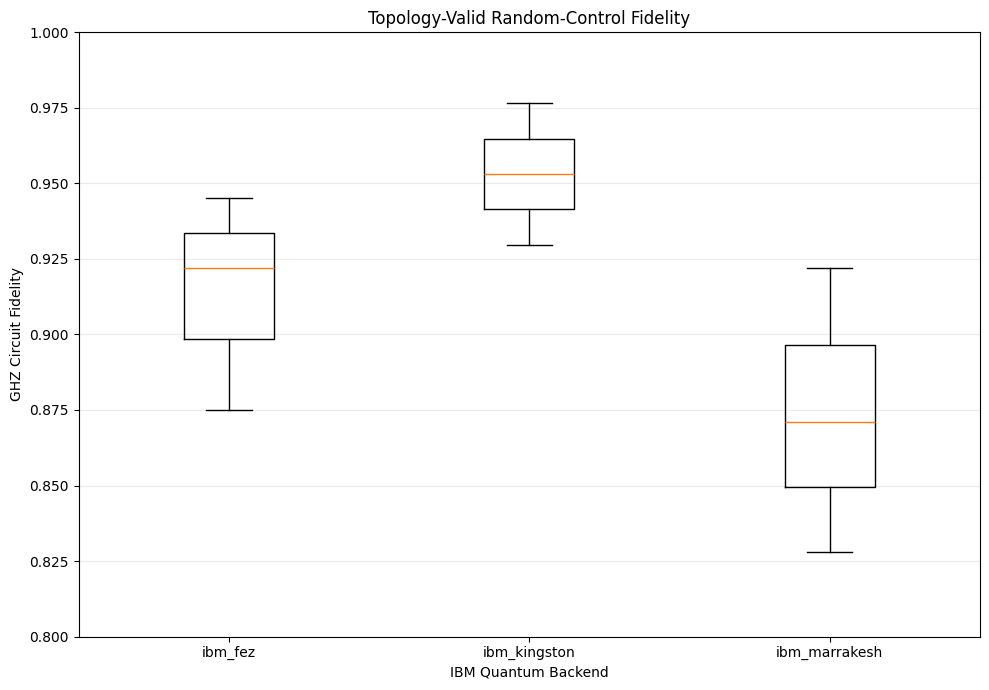


Saved: figures\final_hardware_random_controls.png


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# Load final hardware results
# ---------------------------------------------------------

df = pd.read_csv("results/final_level2/final_hardware_results.csv")

backend_order = [
    "ibm_fez",
    "ibm_kingston",
    "ibm_marrakesh"
]

# Only the 3 random controls
random_df = df[
    df["group"].isin([
        "random_1",
        "random_2",
        "random_3"
    ])
].copy()

# ---------------------------------------------------------
# Prepare data
# ---------------------------------------------------------

data = [
    random_df[
        random_df["backend"] == backend
    ]["fidelity"].values
    for backend in backend_order
]

print("=" * 70)
print("RANDOM HARDWARE CONTROL RESULTS")
print("=" * 70)

for backend, values in zip(backend_order, data):
    print(
        f"{backend}: "
        f"mean={values.mean():.4f}, "
        f"min={values.min():.4f}, "
        f"max={values.max():.4f}"
    )

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.boxplot(
    data,
    labels=backend_order
)

plt.xlabel("IBM Quantum Backend")
plt.ylabel("GHZ Circuit Fidelity")

plt.title(
    "Topology-Valid Random-Control Fidelity"
)

plt.ylim(0.80, 1.00)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

output = Path(
    "figures/final_hardware_random_controls.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved: {output}")

MODEL IMPROVEMENT OVER RANDOM CONTROL
               model_a  model_b  model_c
ibm_fez         0.0430   0.0586   0.0352
ibm_kingston   -0.0273   0.0273   0.0156
ibm_marrakesh   0.0872   0.0951   0.0794


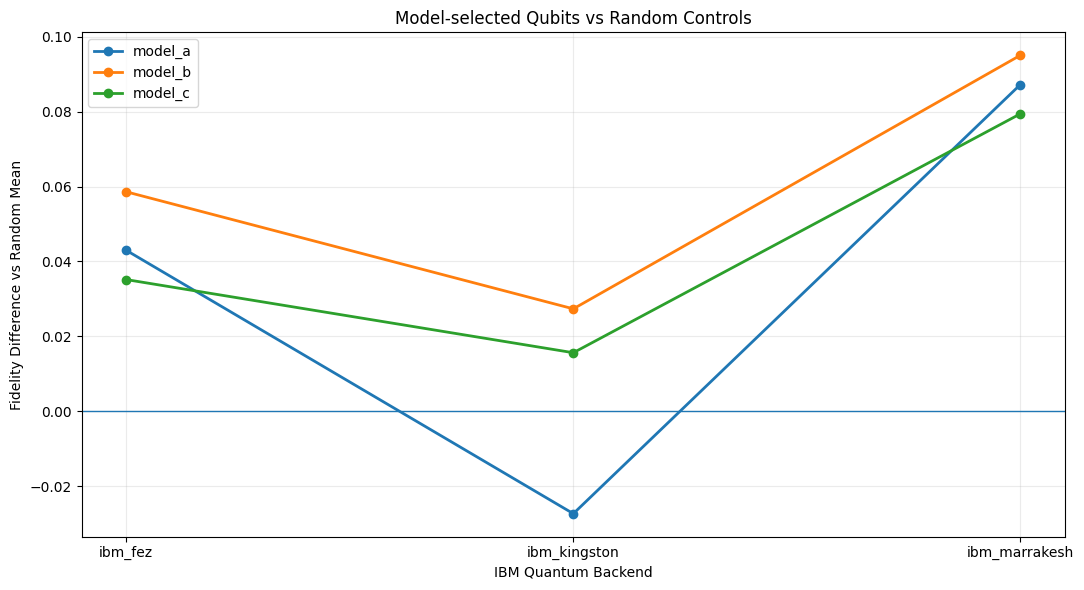


Saved: figures\final_hardware_improvement.png


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# Load final hardware results
# ---------------------------------------------------------

df = pd.read_csv("results/final_level2/final_hardware_results.csv")

backend_order = [
    "ibm_fez",
    "ibm_kingston",
    "ibm_marrakesh"
]

model_order = [
    "model_a",
    "model_b",
    "model_c"
]

# ---------------------------------------------------------
# Model fidelity
# ---------------------------------------------------------

model_df = (
    df[df["group"].isin(model_order)]
    .groupby(["backend", "group"])["fidelity"]
    .mean()
    .unstack()
    .reindex(backend_order)
)

# ---------------------------------------------------------
# Random baseline
# ---------------------------------------------------------

random_mean = (
    df[
        df["group"].isin([
            "random_1",
            "random_2",
            "random_3"
        ])
    ]
    .groupby("backend")["fidelity"]
    .mean()
    .reindex(backend_order)
)

# ---------------------------------------------------------
# Improvement over random
# ---------------------------------------------------------

improvement = pd.DataFrame(index=backend_order)

for model in model_order:
    improvement[model] = (
        model_df[model] - random_mean
    )

print("=" * 70)
print("MODEL IMPROVEMENT OVER RANDOM CONTROL")
print("=" * 70)
print(improvement.round(4))

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

plt.figure(figsize=(11, 6))

for model in model_order:
    plt.plot(
        backend_order,
        improvement[model].values,
        marker="o",
        linewidth=2,
        label=model
    )

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("IBM Quantum Backend")
plt.ylabel("Fidelity Difference vs Random Mean")

plt.title(
    "Model-selected Qubits vs Random Controls"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)

output = Path(
    "figures/final_hardware_improvement.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print()
print(f"Saved: {output}")

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# TEMPORAL MODEL COMPARISON
# Historical vs 7-day vs 30-day
# ============================================================

PROJECT_ROOT = Path.cwd()

# If notebook is inside notebooks/, move to project root
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

FIGURES_DIR.mkdir(exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Results dir  :", RESULTS_DIR)
print("Figures dir  :", FIGURES_DIR)

# ------------------------------------------------------------
# Load historical model results
# ------------------------------------------------------------

historical_file = RESULTS_DIR / "lobo_results.csv"

historical = pd.read_csv(historical_file)

print("\nHistorical columns:")
print(historical.columns.tolist())

# ------------------------------------------------------------
# Automatically find backend and AUC columns
# ------------------------------------------------------------

def find_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


backend_col = find_column(
    historical,
    ["test_backend", "backend", "test_backend_name"]
)

auc_col = find_column(
    historical,
    ["auc", "AUC", "mean_auc", "roc_auc"]
)

if backend_col is None or auc_col is None:
    raise ValueError(
        "Could not identify backend/AUC columns in lobo_results.csv.\n"
        f"Columns found: {historical.columns.tolist()}"
    )

historical_plot = historical[[backend_col, auc_col]].copy()

historical_plot.columns = ["backend", "auc"]

historical_plot["model"] = "Historical"

# ------------------------------------------------------------
# Load Model B / Model C results
# ------------------------------------------------------------

bc_file = RESULTS_DIR / "model_b_c_lobo_all_results.csv"

bc = pd.read_csv(bc_file)

print("\nModel B/C columns:")
print(bc.columns.tolist())

# Automatically locate columns
backend_col_bc = find_column(
    bc,
    ["test_backend", "backend", "test_backend_name"]
)

auc_col_bc = find_column(
    bc,
    ["auc", "AUC", "mean_auc", "roc_auc"]
)

model_col_bc = find_column(
    bc,
    ["model", "model_name", "model_version"]
)

if backend_col_bc is None or auc_col_bc is None or model_col_bc is None:
    raise ValueError(
        "Could not identify model/backend/AUC columns in "
        "model_b_c_lobo_all_results.csv.\n"
        f"Columns found: {bc.columns.tolist()}"
    )

bc_plot = bc[
    [backend_col_bc, model_col_bc, auc_col_bc]
].copy()

bc_plot.columns = ["backend", "model", "auc"]

# ------------------------------------------------------------
# Normalize model names
# ------------------------------------------------------------

def normalize_model_name(x):

    x = str(x).lower().strip()

    if "7" in x or "model_b" in x or x == "b":
        return "7-day"

    if "30" in x or "model_c" in x or x == "c":
        return "30-day"

    if "historical" in x or "model_a" in x or x == "a":
        return "Historical"

    return str(x)


bc_plot["model"] = bc_plot["model"].apply(normalize_model_name)

historical_plot["model"] = "Historical"

# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

plot_df = pd.concat(
    [
        historical_plot,
        bc_plot
    ],
    ignore_index=True
)

# Keep only the three temporal models
plot_df = plot_df[
    plot_df["model"].isin(
        ["Historical", "7-day", "30-day"]
    )
].copy()

# Make sure AUC is numeric
plot_df["auc"] = pd.to_numeric(
    plot_df["auc"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["backend", "auc"]
)

# ------------------------------------------------------------
# Average duplicate rows if present
# ------------------------------------------------------------

plot_df = (
    plot_df
    .groupby(
        ["backend", "model"],
        as_index=False
    )["auc"]
    .mean()
)

print("\nFinal comparison data:")
print(
    plot_df
    .sort_values(["backend", "model"])
    .to_string(index=False)
)

# ------------------------------------------------------------
# Pivot for plotting
# ------------------------------------------------------------

order = [
    "Historical",
    "7-day",
    "30-day"
]

pivot = plot_df.pivot(
    index="backend",
    columns="model",
    values="auc"
)

# Keep desired model order
pivot = pivot.reindex(
    columns=[
        x for x in order
        if x in pivot.columns
    ]
)

print("\nPivot:")
display(pivot)

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6.5)
)

x = np.arange(len(pivot.index))

width = 0.24

models = list(pivot.columns)

offsets = np.linspace(
    -width,
    width,
    len(models)
)

bars = []

for model, offset in zip(models, offsets):

    values = pivot[model].values

    bar = ax.bar(
        x + offset,
        values,
        width=width,
        label=model
    )

    bars.append(bar)

    # Add AUC values above bars
    for rect, value in zip(bar, values):

        if pd.notna(value):

            ax.text(
                rect.get_x() +
                rect.get_width() / 2,
                value + 0.008,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=10
            )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_title(
    "Cross-Backend Performance Across Temporal Training Windows",
    fontsize=16,
    pad=15
)

ax.set_ylabel(
    "LOBO AUC",
    fontsize=12
)

ax.set_xlabel(
    "Test Backend",
    fontsize=12
)

ax.set_xticks(x)

ax.set_xticklabels(
    pivot.index,
    fontsize=11
)

ax.set_ylim(
    max(0, pivot.min().min() - 0.08),
    min(1.0, pivot.max().max() + 0.08)
)

ax.legend(
    title="Training window",
    frameon=True
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_file = (
    FIGURES_DIR /
    "model_temporal_window_comparison.png"
)

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output_file)

Project root : D:\Downloads\uday projects\ibm_circuits
Results dir  : D:\Downloads\uday projects\ibm_circuits\results
Figures dir  : D:\Downloads\uday projects\ibm_circuits\figures


FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Downloads\\uday projects\\ibm_circuits\\results\\lobo_results.csv'